In [391]:
!pip install albumentations --quiet

In [392]:
import tensorflow as tf
from tensorflow.keras import layers, models, Model, callbacks
from tensorflow.keras.layers import (
    Input, Conv2D, BatchNormalization, Activation, Add,
    MaxPooling2D, UpSampling2D, Concatenate, Multiply, Dropout
)
import os
import numpy as np
import matplotlib.pyplot as plt
import cv2
import albumentations as A
from datetime import datetime
from sklearn.metrics import confusion_matrix
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# GPU check
print(f"TensorFlow Version: {tf.__version__}")
print(f"GPU Available: {tf.config.list_physical_devices('GPU')}")

TensorFlow Version: 2.19.0
GPU Available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


In [393]:
class Config:
    DATA_PATH = ""  
    
    # Image settings
    ORIG_WIDTH = 4096
    ORIG_HEIGHT = 256
    PATCH_SIZE = 256
    
    # Training settings
    BATCH_SIZE = 16  
    EPOCHS = 200     
    LEARNING_RATE = 1e-4
    
    # Data balance settings 
    PATCHES_PER_IMAGE = 16  # Number of patches to extract from each image
    DEFECT_PATCH_RATIO = 0.5  # 50% of patches will be defect-centered
    MIN_DEFECT_PIXELS = 200  # At least 500 pixels should be defect
    
    # Augmentation
    AUGMENT_PROB = 0.8

# Automatically find dataset path
for root, dirs, files in os.walk("/kaggle/input"):
    if "train" in dirs and "val" in dirs:
        Config.DATA_PATH = root
        print(f"Dataset found: {Config.DATA_PATH}")
        break

if not Config.DATA_PATH:
    print("WARNING: Dataset not found. Please check /kaggle/input")

Dataset found: /kaggle/input/aitex-dataset/aitex_dataset_processed


In [394]:
import os

# Set image and mask directories
train_image_dir = os.path.join(Config.DATA_PATH, "train", "images")
train_mask_dir = os.path.join(Config.DATA_PATH, "train", "masks")
val_image_dir = os.path.join(Config.DATA_PATH, "val", "images")
val_mask_dir = os.path.join(Config.DATA_PATH, "val", "masks")

# Filter valid train pairs
valid_train_mask_files = [f for f in os.listdir(train_mask_dir) if f.endswith('.png')]
train_image_mask_pairs = []
for mask_file in valid_train_mask_files:
    image_file = mask_file.replace('_mask.png', '.png')
    image_path = os.path.join(train_image_dir, image_file)
    mask_path = os.path.join(train_mask_dir, mask_file)
    if os.path.exists(image_path):
        train_image_mask_pairs.append((image_path, mask_path))

# Filter valid val pairs
valid_val_mask_files = [f for f in os.listdir(val_mask_dir) if f.endswith('.png')]
val_image_mask_pairs = []
for mask_file in valid_val_mask_files:
    image_file = mask_file.replace('_mask.png', '.png')
    image_path = os.path.join(val_image_dir, image_file)
    mask_path = os.path.join(val_mask_dir, mask_file)
    if os.path.exists(image_path):
        val_image_mask_pairs.append((image_path, mask_path))

# Split into separate lists
train_image_paths = [pair[0] for pair in train_image_mask_pairs]
train_mask_paths = [pair[1] for pair in train_image_mask_pairs]
val_image_paths = [pair[0] for pair in val_image_mask_pairs]
val_mask_paths = [pair[1] for pair in val_image_mask_pairs]

In [395]:
def extract_grid_patches(image, mask, config=Config):
    """
    Extract patches from the image and mask using a grid (non-overlapping).
    Each patch is labeled as defect if it contains at least MIN_DEFECT_PIXELS.
    """
    h, w = image.shape[:2]
    patch_size = config.PATCH_SIZE
    stride = patch_size  # non-overlapping; for overlap use stride < patch_size

    patches_img = []
    patches_mask = []
    is_defect = []

    binary_mask = (mask > 127).astype(np.uint8)

    for y in range(0, h - patch_size + 1, stride):
        for x in range(0, w - patch_size + 1, stride):
            patch_img = image[y:y+patch_size, x:x+patch_size]
            patch_mask = binary_mask[y:y+patch_size, x:x+patch_size]
            defect_pixels = np.count_nonzero(patch_mask)
            # Only count as defect if area is large enough
            is_def = defect_pixels >= config.MIN_DEFECT_PIXELS
            patches_img.append(patch_img)
            patches_mask.append(patch_mask)
            is_defect.append(is_def)
    return patches_img, patches_mask, is_defect

In [396]:
def get_augmentation_pipeline(mode='train'):
    if mode == 'train':
        return A.Compose([
            A.HorizontalFlip(p=0.5),
            A.VerticalFlip(p=0.5),
            A.Rotate(limit=15, border_mode=cv2.BORDER_CONSTANT, value=0, p=0.3),
            A.ShiftScaleRotate(
                shift_limit=0.0625, 
                scale_limit=0.1,
                rotate_limit=10,
                border_mode=cv2.BORDER_CONSTANT,
                value=0,
                p=0.3
            ),
            
            A.RandomBrightnessContrast(
                brightness_limit=0.2,
                contrast_limit=0.2,
                p=0.5
            ),
            A.GaussNoise(var_limit=(10.0, 30.0), p=0.3),
            A.GaussianBlur(blur_limit=(3, 5), p=0.2),
            
            A.ElasticTransform(
                alpha=1,
                sigma=20,
                alpha_affine=20,
                border_mode=cv2.BORDER_CONSTANT,
                value=0,
                p=0.3
            ),
            
            A.OneOf([
                A.GridDistortion(border_mode=cv2.BORDER_CONSTANT, value=0, p=1.0),
                A.OpticalDistortion(distort_limit=0.05, shift_limit=0.05,
                                   border_mode=cv2.BORDER_CONSTANT, value=0, p=1.0),
            ], p=0.2),
        ], additional_targets={'mask': 'mask'})
    else:
        return None

In [397]:
@tf.function
def focal_loss(y_true, y_pred, alpha=0.25, gamma=2.0):
    # FL = -α(1-p)^γ log(p)        y=1 (defect)
    # FL = -(1-α)p^γ log(1-p)      y=0 (background)
    
    y_pred = tf.clip_by_value(y_pred, 1e-7, 1.0 - 1e-7)
    
    # positive classes (defects)
    focal_pos = -alpha * tf.pow(1.0 - y_pred, gamma) * y_true * tf.math.log(y_pred)
    
    # negative classes (background)
    focal_neg = -(1.0 - alpha) * tf.pow(y_pred, gamma) * (1.0 - y_true) * tf.math.log(1.0 - y_pred)
    
    focal = focal_pos + focal_neg
    
    return tf.reduce_mean(focal)

@tf.function
def dice_loss(y_true, y_pred, smooth=1e-6):
    """
    The Dice coefficient measures the intersection/union ratio. 
    It works well with unbalanced datasets because it is proportional.
    
    Dice = 2 * |A ∩ B| / (|A| + |B|)
    """
    y_true_f = tf.reshape(y_true, [-1])
    y_pred_f = tf.reshape(y_pred, [-1])
    
    intersection = tf.reduce_sum(y_true_f * y_pred_f)
    union = tf.reduce_sum(y_true_f) + tf.reduce_sum(y_pred_f)
    
    dice = (2.0 * intersection + smooth) / (union + smooth)
    
    return 1.0 - dice

@tf.function
def combined_loss(y_true, y_pred):
    """
    Combine loss: Focal + Dice
    
    Focal Loss: It resolves class inequality.
    Dice Loss: Measures segmentation quality.
    
    These two methods provide both balanced learning and good segmentation.
    """
    focal = focal_loss(y_true, y_pred, alpha=0.25, gamma=2.0)
    dice = dice_loss(y_true, y_pred)
    
    return 0.5 * focal + 0.5 * dice

In [398]:
def conv_block(x, filters, kernel_size=3, activation='relu', use_bn=True, dropout=0.0):
    """
    Standard convolutional block: Conv -> BN -> ReLU -> Conv -> BN -> ReLU
    """
    x = Conv2D(filters, kernel_size, padding='same')(x)
    if use_bn:
        x = BatchNormalization()(x)
    x = Activation(activation)(x)
    if dropout > 0:
        x = Dropout(dropout)(x)

    x = Conv2D(filters, kernel_size, padding='same')(x)
    if use_bn:
        x = BatchNormalization()(x)
    x = Activation(activation)(x)

    return x

def attention_gate(x, g, filters):
    """
    Attention Gate - Learns what to focus on in the skip connection of the decoder.

    Args:
        x: Skip connection from encoder (high resolution)
        g: Gating signal from decoder (low resolution, semantic)
        filters: Number of attention filters
    """
    # Transform skip connection
    theta_x = Conv2D(filters, kernel_size=1, padding='same')(x)  # No strides=2

    # Transform gating signal
    phi_g = Conv2D(filters, kernel_size=1, padding='same')(g)

    # Combine and activate
    concat = Add()([theta_x, phi_g])
    relu = Activation('relu')(concat)

    # Generate attention coefficients (between 0-1)
    psi = Conv2D(1, kernel_size=1, padding='same')(relu)
    psi = Activation('sigmoid')(psi)

    # Apply attention: important regions close to 1, unimportant close to 0
    output = Multiply()([x, psi])

    return output

In [399]:
def build_attention_unet(input_shape=(256, 256, 1), filters_base=32):
    """
    Attention U-Net model.

    Architecture:
    Encoder: 4 levels, increasing filters (32 -> 64 -> 128 -> 256)
    Bottleneck: 512 filters
    Decoder: 4 levels, with attention gates

    Attention gates help the decoder focus on relevant features.
    """
    inputs = Input(input_shape)

    # Encoder
    conv1 = conv_block(inputs, filters_base, dropout=0.1)
    pool1 = MaxPooling2D((2, 2))(conv1)

    conv2 = conv_block(pool1, filters_base * 2, dropout=0.1)
    pool2 = MaxPooling2D((2, 2))(conv2)

    conv3 = conv_block(pool2, filters_base * 4, dropout=0.2)
    pool3 = MaxPooling2D((2, 2))(conv3)

    conv4 = conv_block(pool3, filters_base * 8, dropout=0.2)
    pool4 = MaxPooling2D((2, 2))(conv4)

    # Bottleneck
    conv5 = conv_block(pool4, filters_base * 16, dropout=0.3)

    # Decoder with Attention Gates
    up6 = UpSampling2D(size=(2, 2), interpolation='bilinear')(conv5)
    att6 = attention_gate(conv4, up6, filters_base * 8)
    merge6 = Concatenate()([up6, att6])
    conv6 = conv_block(merge6, filters_base * 8, dropout=0.2)

    up7 = UpSampling2D(size=(2, 2), interpolation='bilinear')(conv6)
    att7 = attention_gate(conv3, up7, filters_base * 4)
    merge7 = Concatenate()([up7, att7])
    conv7 = conv_block(merge7, filters_base * 4, dropout=0.2)

    up8 = UpSampling2D(size=(2, 2), interpolation='bilinear')(conv7)
    att8 = attention_gate(conv2, up8, filters_base * 2)
    merge8 = Concatenate()([up8, att8])
    conv8 = conv_block(merge8, filters_base * 2, dropout=0.1)

    up9 = UpSampling2D(size=(2, 2), interpolation='bilinear')(conv8)
    att9 = attention_gate(conv1, up9, filters_base)
    merge9 = Concatenate()([up9, att9])
    conv9 = conv_block(merge9, filters_base, dropout=0.1)

    # Output
    outputs = Conv2D(1, kernel_size=1, activation='sigmoid', name='output')(conv9)

    model = Model(inputs=[inputs], outputs=[outputs], name='Attention_UNet')

    return model

In [400]:
class AITexDataset:
    """
    AITex dataset with smart patch sampling.
    """
    def __init__(self, image_paths, mask_paths, config=Config, mode='train'):
        self.image_paths = image_paths
        self.mask_paths = mask_paths
        self.config = config
        self.mode = mode
        self.augmentation = get_augmentation_pipeline(mode)
        
        # Extract all patches in advance
        self.patches = []
        self.labels = []
        self._extract_all_patches()
    
    def _extract_all_patches(self):
        print(f"\n{'='*70}")
        print(f"Extracting patches for {self.mode.upper()} set...")
        print(f"{'='*70}")

        total_defect_patches = 0
        total_normal_patches = 0

        for idx, (img_path, mask_path) in enumerate(zip(self.image_paths, self.mask_paths)):
            # Read image and mask
            image = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
            mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
            if image is None or mask is None:
                print(f"WARNING: Could not read {os.path.basename(img_path)}")
                continue

            # Binarize mask and optionally overwrite
            binary_mask = (mask > 127).astype(np.uint8) * 255
            # Uncomment the next line if you want to overwrite the mask file
            # cv2.imwrite(mask_path, binary_mask)

            defect_pixels = np.count_nonzero(binary_mask)
            if defect_pixels > 0:
                print(f"This mask contains defect pixels (mask > 127): {defect_pixels}")
            else:
                print("This mask does NOT contain defect pixels.")

            # Normalize image
            image = image.astype(np.float32) / 255.0
            # Use binary mask for patch extraction and normalization
            mask = (binary_mask > 0).astype(np.float32)

            # Smart patch extraction
            patches_img, patches_mask, is_defect = extract_defect_centered_patches(
                image, mask, self.config
            )

            # Save each patch
            for p_img, p_mask, defect_flag in zip(patches_img, patches_mask, is_defect):
                self.patches.append({
                    'image': p_img,
                    'mask': p_mask,
                    'is_defect': defect_flag
                })
                self.labels.append(1 if defect_flag else 0)

                if defect_flag:
                    total_defect_patches += 1
                else:
                    total_normal_patches += 1

            if (idx + 1) % 50 == 0:
                print(f"Processed {idx + 1}/{len(self.image_paths)} images...")

        print(f"\n{'='*70}")
        print(f"EXTRACTION COMPLETE:")
        print(f"  Total patches: {len(self.patches)}")
        print(f"  Defect patches: {total_defect_patches} ({100*total_defect_patches/len(self.patches):.1f}%)")
        print(f"  Normal patches: {total_normal_patches} ({100*total_normal_patches/len(self.patches):.1f}%)")
        print(f"{'='*70}\n")
    
    def __len__(self):
        return len(self.patches)
    
    def get_item(self, idx):
        """
        Get a sample with augmentation.
        """
        patch = self.patches[idx]
        image = patch['image'].copy()
        mask = patch['mask'].copy()
        
        # Apply augmentation (only for training)
        if self.augmentation and self.mode == 'train':
            augmented = self.augmentation(image=image, mask=mask)
            image = augmented['image']
            mask = augmented['mask']
        
        # Add channel dimension
        image = np.expand_dims(image, axis=-1)
        mask = np.expand_dims(mask, axis=-1)
        
        return image.astype(np.float32), mask.astype(np.float32)

In [401]:
def create_balanced_tf_dataset(dataset, batch_size, mode='train'):
    """
    Create a balanced TensorFlow dataset.

    Training: Oversample defect patches for 50-50 balance.
    Validation: Use as is (real distribution).
    """
    if mode == 'train':
        print(f"\n{'='*70}")
        print("CREATING BALANCED TRAINING DATASET")
        print(f"{'='*70}")
        
        # Separate defect and normal indices
        defect_indices = [i for i, label in enumerate(dataset.labels) if label == 1]
        normal_indices = [i for i, label in enumerate(dataset.labels) if label == 0]
        
        print(f"Original distribution:")
        print(f"  Defect: {len(defect_indices)}")
        print(f"  Normal: {len(normal_indices)}")
        print(f"  Ratio: 1:{len(normal_indices)/max(len(defect_indices), 1):.1f}")
        
        # Oversample minority class (defects)
        num_defects = len(defect_indices)
        num_normals = len(normal_indices)
        
        if num_defects < num_normals:
            multiplier = num_normals // num_defects
            balanced_indices = defect_indices * multiplier + normal_indices
            
            print(f"\nAfter balancing:")
            print(f"  Defect: {len(defect_indices) * multiplier}")
            print(f"  Normal: {len(normal_indices)}")
            print(f"  Ratio: ~1:1")
        else:
            balanced_indices = list(range(len(dataset)))
        
        np.random.shuffle(balanced_indices)
        indices = balanced_indices
        print(f"  Total training samples: {len(indices)}")
        print(f"{'='*70}\n")
    else:
        indices = list(range(len(dataset)))
    
    # Generator
    def generator():
        for idx in indices:
            yield dataset.get_item(idx)
    
    # TensorFlow dataset
    tf_dataset = tf.data.Dataset.from_generator(
        generator,
        output_signature=(
            tf.TensorSpec(shape=(256, 256, 1), dtype=tf.float32),
            tf.TensorSpec(shape=(256, 256, 1), dtype=tf.float32),
        )
    )
    
    if mode == 'train':
        tf_dataset = tf_dataset.shuffle(1000)
    
    tf_dataset = tf_dataset.batch(batch_size)
    tf_dataset = tf_dataset.prefetch(tf.data.AUTOTUNE)
    
    return tf_dataset

In [402]:
def calculate_metrics(y_true, y_pred, threshold=0.3):
    """
    Calculate segmentation metrics.

    Returns:
        dict: dice, iou, recall, precision, f1, tp, fp, fn, tn
    """
    y_pred_bin = (y_pred > threshold).astype(np.float32)
    y_true_f = y_true.flatten()
    y_pred_f = y_pred_bin.flatten()
    tp = np.sum(y_true_f * y_pred_f)
    fp = np.sum((1 - y_true_f) * y_pred_f)
    fn = np.sum(y_true_f * (1 - y_pred_f))
    tn = np.sum((1 - y_true_f) * (1 - y_pred_f))
    dice = (2 * tp) / (2 * tp + fp + fn + 1e-7)
    iou = tp / (tp + fp + fn + 1e-7)
    recall = tp / (tp + fn + 1e-7)
    precision = tp / (tp + fp + 1e-7)
    f1 = 2 * (precision * recall) / (precision + recall + 1e-7)
    return {
        'dice': dice,
        'iou': iou,
        'recall': recall,
        'precision': precision,
        'f1': f1,
        'tp': int(tp),
        'fp': int(fp),
        'fn': int(fn),
        'tn': int(tn)
    }

def multi_threshold_evaluation(model, val_dataset, save_path=None):
    """
    Evaluate at multiple thresholds and find the best one.
    """
    print(f"\n{'='*70}")
    print("MULTI-THRESHOLD EVALUATION")
    print(f"{'='*70}")
    y_true_all = []
    y_pred_all = []
    print("Generating predictions...")
    for images, masks in val_dataset:
        preds = model.predict(images, verbose=0)
        y_true_all.append(masks.numpy())
        y_pred_all.append(preds)
    y_true = np.concatenate(y_true_all, axis=0)
    y_pred = np.concatenate(y_pred_all, axis=0)
    thresholds = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7]
    results = []
    print(f"\n{'Threshold':<12}{'Dice':<10}{'IoU':<10}{'Recall':<10}{'Precision':<10}{'F1':<10}")
    print("-" * 70)
    for thresh in thresholds:
        metrics = calculate_metrics(y_true, y_pred, threshold=thresh)
        results.append((thresh, metrics))
        print(f"{thresh:<12.2f}{metrics['dice']:<10.4f}{metrics['iou']:<10.4f}"
              f"{metrics['recall']:<10.4f}{metrics['precision']:<10.4f}{metrics['f1']:<10.4f}")
    best_thresh, best_metrics = max(results, key=lambda x: x[1]['f1'])
    print(f"\n{'='*70}")
    print(f"BEST THRESHOLD: {best_thresh:.2f}")
    print(f"  Dice: {best_metrics['dice']:.4f}")
    print(f"  IoU: {best_metrics['iou']:.4f}")
    print(f"  Recall: {best_metrics['recall']:.4f}")
    print(f"  Precision: {best_metrics['precision']:.4f}")
    print(f"  F1: {best_metrics['f1']:.4f}")
    print(f"{'='*70}\n")
    # Plot
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
    threshs = [r[0] for r in results]
    dices = [r[1]['dice'] for r in results]
    recalls = [r[1]['recall'] for r in results]
    precisions = [r[1]['precision'] for r in results]
    ax1.plot(threshs, dices, 'o-', label='Dice', linewidth=2, markersize=8)
    ax1.plot(threshs, recalls, 's-', label='Recall', linewidth=2, markersize=8)
    ax1.plot(threshs, precisions, '^-', label='Precision', linewidth=2, markersize=8)
    ax1.axvline(best_thresh, color='r', linestyle='--', linewidth=2, label=f'Best={best_thresh:.2f}')
    ax1.set_xlabel('Threshold', fontsize=12)
    ax1.set_ylabel('Score', fontsize=12)
    ax1.set_title('Metrics vs Threshold', fontsize=14, fontweight='bold')
    ax1.legend(fontsize=11)
    ax1.grid(True, alpha=0.3)
    f1s = [r[1]['f1'] for r in results]
    ax2.plot(threshs, f1s, 'o-', color='green', linewidth=2, markersize=8)
    ax2.axvline(best_thresh, color='r', linestyle='--', linewidth=2, label=f'Best={best_thresh:.2f}')
    ax2.set_xlabel('Threshold', fontsize=12)
    ax2.set_ylabel('F1 Score', fontsize=12)
    ax2.set_title('F1 Score vs Threshold', fontsize=14, fontweight='bold')
    ax2.legend(fontsize=11)
    ax2.grid(True, alpha=0.3)
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=150, bbox_inches='tight')
    plt.show()
    return best_thresh, best_metrics

In [403]:
def visualize_predictions(model, val_dataset, num_samples=6, threshold=0.3):
    """
    Visualize model predictions.
    """
    for images, masks in val_dataset.take(1):
        preds = model.predict(images, verbose=0)
        n = min(num_samples, images.shape[0])
        fig, axes = plt.subplots(n, 3, figsize=(12, n * 3))
        if n == 1:
            axes = axes.reshape(1, -1)
        for i in range(n):
            axes[i, 0].imshow(images[i, :, :, 0], cmap='gray')
            axes[i, 0].set_title('Input Image', fontsize=12, fontweight='bold')
            axes[i, 0].axis('off')
            axes[i, 1].imshow(masks[i, :, :, 0], cmap='gray')
            axes[i, 1].set_title('Ground Truth', fontsize=12, fontweight='bold')
            axes[i, 1].axis('off')
            pred_binary = (preds[i, :, :, 0] > threshold).astype(float)
            axes[i, 2].imshow(pred_binary, cmap='gray')
            metrics = calculate_metrics(
                masks[i:i+1].numpy(), 
                preds[i:i+1], 
                threshold=threshold
            )
            axes[i, 2].set_title(
                f"Prediction (Dice={metrics['dice']:.3f})", 
                fontsize=12, 
                fontweight='bold'
            )
            axes[i, 2].axis('off')
        plt.tight_layout()
        plt.show()
        break

def plot_training_history(history):
    """
    Visualize training history.
    """
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
    ax1.plot(history.history['loss'], label='Train Loss', linewidth=2)
    ax1.plot(history.history['val_loss'], label='Val Loss', linewidth=2)
    ax1.set_xlabel('Epoch', fontsize=12)
    ax1.set_ylabel('Loss', fontsize=12)
    ax1.set_title('Training and Validation Loss', fontsize=14, fontweight='bold')
    ax1.legend(fontsize=11)
    ax1.grid(True, alpha=0.3)
    ax2.plot(history.history['accuracy'], label='Train Accuracy', linewidth=2)
    ax2.plot(history.history['val_accuracy'], label='Val Accuracy', linewidth=2)
    ax2.set_xlabel('Epoch', fontsize=12)
    ax2.set_ylabel('Accuracy', fontsize=12)
    ax2.set_title('Training and Validation Accuracy', fontsize=14, fontweight='bold')
    ax2.legend(fontsize=11)
    ax2.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

In [404]:
def build_hrnet(input_shape=(256, 256, 1), base_filters=32):
    """
    Simplified HRNet encoder-decoder for segmentation.
    Note: This is not a full HRNet, but a basic multi-resolution block.
    """
    inputs = Input(input_shape)

    # Stage 1
    x1 = conv_block(inputs, base_filters)
    p1 = MaxPooling2D((2, 2))(x1)

    # Stage 2
    x2 = conv_block(p1, base_filters * 2)
    p2 = MaxPooling2D((2, 2))(x2)

    # Stage 3
    x3 = conv_block(p2, base_filters * 4)
    p3 = MaxPooling2D((2, 2))(x3)

    # Stage 4
    x4 = conv_block(p3, base_filters * 8)

    # Multi-resolution fusion (simple upsampling and concatenation)
    u3 = UpSampling2D((2, 2), interpolation='bilinear')(x4)
    f3 = Concatenate()([u3, x3])

    u2 = UpSampling2D((2, 2), interpolation='bilinear')(f3)
    f2 = Concatenate()([u2, x2])

    u1 = UpSampling2D((2, 2), interpolation='bilinear')(f2)
    f1 = Concatenate()([u1, x1])

    outputs = Conv2D(1, (1, 1), activation='sigmoid')(f1)

    model = Model(inputs, outputs, name='HRNet_Simple')
    return model

In [405]:
# Define callbacks for training
callbacks_list = [
    callbacks.ModelCheckpoint(
        'best_model.h5',
        monitor='val_loss',
        save_best_only=True,
        mode='min',
        verbose=1
    ),
    callbacks.EarlyStopping(
        monitor='val_loss',
        patience=30,
        restore_best_weights=True,
        verbose=1
    ),
    callbacks.ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.5,
        patience=10,
        min_lr=1e-7,
        verbose=1
    ),
    callbacks.CSVLogger('training_log.csv'),
]

# Prepare image and mask file lists using only valid .png mask files
train_image_dir = os.path.join(Config.DATA_PATH, "train", "images")
train_mask_dir = os.path.join(Config.DATA_PATH, "train", "masks")
val_image_dir = os.path.join(Config.DATA_PATH, "val", "images")
val_mask_dir = os.path.join(Config.DATA_PATH, "val", "masks")

# Filter valid train pairs
valid_train_mask_files = [f for f in os.listdir(train_mask_dir) if f.endswith('.png')]
train_image_mask_pairs = []
for mask_file in valid_train_mask_files:
    image_file = mask_file.replace('_mask.png', '.png')
    image_path = os.path.join(train_image_dir, image_file)
    mask_path = os.path.join(train_mask_dir, mask_file)
    if os.path.exists(image_path):
        train_image_mask_pairs.append((image_path, mask_path))

# Filter valid val pairs
valid_val_mask_files = [f for f in os.listdir(val_mask_dir) if f.endswith('.png')]
val_image_mask_pairs = []
for mask_file in valid_val_mask_files:
    image_file = mask_file.replace('_mask.png', '.png')
    image_path = os.path.join(val_image_dir, image_file)
    mask_path = os.path.join(val_mask_dir, mask_file)
    if os.path.exists(image_path):
        val_image_mask_pairs.append((image_path, mask_path))

# Split into separate lists
train_images = [pair[0] for pair in train_image_mask_pairs]
train_masks = [pair[1] for pair in train_image_mask_pairs]
val_images = [pair[0] for pair in val_image_mask_pairs]
val_masks = [pair[1] for pair in val_image_mask_pairs]

# Create dataset objects
train_dataset_obj = AITexDataset(train_images, train_masks, Config, mode='train')
val_dataset_obj = AITexDataset(val_images, val_masks, Config, mode='val')

# Create TensorFlow datasets
train_dataset = create_balanced_tf_dataset(train_dataset_obj, Config.BATCH_SIZE, mode='train')
val_dataset = create_balanced_tf_dataset(val_dataset_obj, Config.BATCH_SIZE, mode='val')


Extracting patches for TRAIN set...
This mask contains defect pixels (mask > 127): 4796
This mask contains defect pixels (mask > 127): 38
This mask contains defect pixels (mask > 127): 231
This mask contains defect pixels (mask > 127): 1190
This mask contains defect pixels (mask > 127): 301
This mask contains defect pixels (mask > 127): 326
This mask contains defect pixels (mask > 127): 102
This mask contains defect pixels (mask > 127): 15
This mask contains defect pixels (mask > 127): 14
This mask contains defect pixels (mask > 127): 29
This mask contains defect pixels (mask > 127): 15
This mask contains defect pixels (mask > 127): 287
This mask contains defect pixels (mask > 127): 20
This mask contains defect pixels (mask > 127): 135
This mask contains defect pixels (mask > 127): 484
This mask contains defect pixels (mask > 127): 32
This mask contains defect pixels (mask > 127): 12
This mask contains defect pixels (mask > 127): 28
This mask contains defect pixels (mask > 127): 53
Th

Mask: /kaggle/input/aitex-dataset/aitex_dataset_processed/val/masks/0012_006_02_mask.png
Unique values and counts: {np.uint8(0): np.int64(1047160), np.uint8(8): np.int64(22), np.uint8(10): np.int64(1), np.uint8(16): np.int64(32), np.uint8(20): np.int64(1), np.uint8(25): np.int64(20), np.uint8(32): np.int64(3), np.uint8(33): np.int64(19), np.uint8(42): np.int64(3), np.uint8(43): np.int64(25), np.uint8(51): np.int64(23), np.uint8(53): np.int64(3), np.uint8(60): np.int64(15), np.uint8(64): np.int64(3), np.uint8(69): np.int64(26), np.uint8(76): np.int64(2), np.uint8(79): np.int64(19), np.uint8(86): np.int64(2), np.uint8(88): np.int64(13), np.uint8(98): np.int64(28), np.uint8(107): np.int64(19), np.uint8(117): np.int64(14), np.uint8(121): np.int64(4), np.uint8(126): np.int64(17), np.uint8(133): np.int64(6), np.uint8(136): np.int64(8), np.uint8(145): np.int64(5), np.uint8(146): np.int64(17), np.uint8(156): np.int64(15), np.uint8(166): np.int64(15), np.uint8(169): np.int64(4), np.uint8(176): 

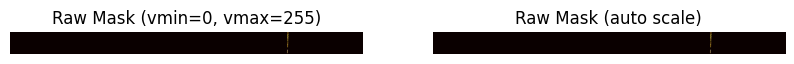

Defect pixels (mask > 127): 1102
This mask contains defect pixels (mask > 127).
------------------------------------------------------------
Mask: /kaggle/input/aitex-dataset/aitex_dataset_processed/val/masks/0093_030_01_mask.png
Unique values and counts: {np.uint8(0): np.int64(1048479), np.uint8(19): np.int64(1), np.uint8(83): np.int64(1), np.uint8(209): np.int64(1), np.uint8(213): np.int64(1), np.uint8(214): np.int64(1), np.uint8(215): np.int64(2), np.uint8(217): np.int64(2), np.uint8(218): np.int64(1), np.uint8(223): np.int64(1), np.uint8(226): np.int64(1), np.uint8(227): np.int64(2), np.uint8(230): np.int64(1), np.uint8(232): np.int64(2), np.uint8(234): np.int64(1), np.uint8(238): np.int64(1), np.uint8(239): np.int64(1), np.uint8(240): np.int64(1), np.uint8(241): np.int64(1), np.uint8(244): np.int64(1), np.uint8(245): np.int64(3), np.uint8(246): np.int64(5), np.uint8(247): np.int64(12), np.uint8(248): np.int64(42), np.uint8(249): np.int64(11), np.uint8(250): np.int64(1)}
Max value:

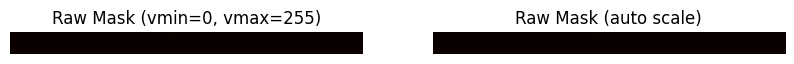

Defect pixels (mask > 127): 95
This mask is considered empty (ignoring tiny noise).
------------------------------------------------------------
Mask: /kaggle/input/aitex-dataset/aitex_dataset_processed/val/masks/0080_036_01_mask.png
Unique values and counts: {np.uint8(0): np.int64(815077), np.uint8(10): np.int64(9), np.uint8(20): np.int64(16), np.uint8(32): np.int64(21), np.uint8(42): np.int64(38), np.uint8(53): np.int64(10), np.uint8(64): np.int64(25), np.uint8(76): np.int64(33), np.uint8(86): np.int64(17), np.uint8(98): np.int64(17), np.uint8(109): np.int64(20), np.uint8(121): np.int64(40), np.uint8(133): np.int64(20), np.uint8(145): np.int64(9), np.uint8(156): np.int64(30), np.uint8(169): np.int64(56), np.uint8(180): np.int64(46), np.uint8(193): np.int64(21), np.uint8(205): np.int64(49), np.uint8(217): np.int64(30), np.uint8(218): np.int64(35), np.uint8(219): np.int64(44), np.uint8(220): np.int64(42), np.uint8(221): np.int64(50), np.uint8(222): np.int64(57), np.uint8(223): np.int64

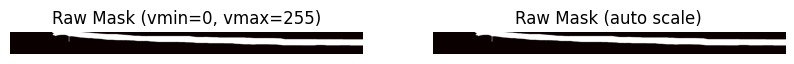

Defect pixels (mask > 127): 233253
This mask contains defect pixels (mask > 127).
------------------------------------------------------------
Mask: /kaggle/input/aitex-dataset/aitex_dataset_processed/val/masks/0066_023_01_mask.png
Unique values and counts: {np.uint8(0): np.int64(1047993), np.uint8(8): np.int64(6), np.uint8(17): np.int64(9), np.uint8(26): np.int64(8), np.uint8(35): np.int64(5), np.uint8(44): np.int64(7), np.uint8(53): np.int64(4), np.uint8(62): np.int64(16), np.uint8(71): np.int64(13), np.uint8(81): np.int64(7), np.uint8(90): np.int64(13), np.uint8(100): np.int64(14), np.uint8(110): np.int64(6), np.uint8(120): np.int64(6), np.uint8(130): np.int64(8), np.uint8(140): np.int64(7), np.uint8(150): np.int64(5), np.uint8(161): np.int64(3), np.uint8(171): np.int64(1), np.uint8(181): np.int64(4), np.uint8(182): np.int64(4), np.uint8(183): np.int64(3), np.uint8(184): np.int64(1), np.uint8(185): np.int64(1), np.uint8(186): np.int64(3), np.uint8(187): np.int64(1), np.uint8(188): n

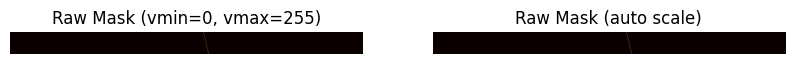

Defect pixels (mask > 127): 469
This mask contains defect pixels (mask > 127).
------------------------------------------------------------
Mask: /kaggle/input/aitex-dataset/aitex_dataset_processed/val/masks/0005_002_01_mask.png
Unique values and counts: {np.uint8(0): np.int64(1046010), np.uint8(10): np.int64(3), np.uint8(20): np.int64(5), np.uint8(30): np.int64(3), np.uint8(41): np.int64(3), np.uint8(52): np.int64(3), np.uint8(62): np.int64(8), np.uint8(73): np.int64(7), np.uint8(84): np.int64(7), np.uint8(95): np.int64(5), np.uint8(106): np.int64(2), np.uint8(117): np.int64(6), np.uint8(128): np.int64(6), np.uint8(140): np.int64(5), np.uint8(151): np.int64(3), np.uint8(163): np.int64(4), np.uint8(175): np.int64(5), np.uint8(187): np.int64(7), np.uint8(198): np.int64(8), np.uint8(210): np.int64(16), np.uint8(211): np.int64(6), np.uint8(212): np.int64(11), np.uint8(213): np.int64(10), np.uint8(214): np.int64(13), np.uint8(215): np.int64(11), np.uint8(216): np.int64(6), np.uint8(217): n

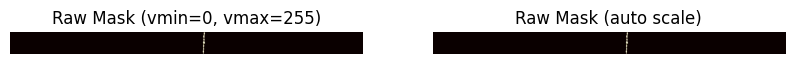

Defect pixels (mask > 127): 2514
This mask contains defect pixels (mask > 127).
------------------------------------------------------------


In [406]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

def debug_mask(mask_path):
    mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
    if mask is None:
        print(f"Could not read mask: {mask_path}")
        return
    unique, counts = np.unique(mask, return_counts=True)
    print(f"Mask: {mask_path}")
    print("Unique values and counts:", dict(zip(unique, counts)))
    print("Max value:", mask.max(), "Min value:", mask.min())
    # Show mask with enhanced contrast
    plt.figure(figsize=(10,3))
    plt.subplot(1,2,1)
    plt.imshow(mask, cmap='hot', vmin=0, vmax=255)
    plt.title('Raw Mask (vmin=0, vmax=255)')
    plt.axis('off')
    plt.subplot(1,2,2)
    plt.imshow(mask, cmap='hot')
    plt.title('Raw Mask (auto scale)')
    plt.axis('off')
    plt.show()
    # Binarize and count
    binary_mask = (mask > 127).astype(np.uint8)
    defect_pixels = np.count_nonzero(binary_mask)
    print("Defect pixels (mask > 127):", defect_pixels)
    if defect_pixels < 200:  # You can adjust this threshold
        print("This mask is considered empty (ignoring tiny noise).")
    else:
        print("This mask contains defect pixels (mask > 127).")
    print("-" * 60)

# Example: check a few masks from your validation set
for i in range(5):
    debug_mask(val_masks[i])

Checking mask-image matching and visualizing samples...
Image: 0018_010_03.png, Mask: 0018_010_03_mask.png
Mask array (unique values): [  0 255]
Nonzero pixel count (mask > 0): 1751
Nonzero pixel count (mask > 127): 1751
This mask contains defect pixels (mask > 127).
Nonzero pixel indices (mask > 127): [[ 168 1122]
 [ 168 1123]
 [ 168 1124]
 ...
 [ 204 1664]
 [ 204 1665]
 [ 204 1666]]


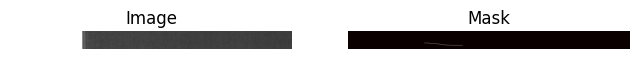

Image: 0046_019_04.png, Mask: 0046_019_04_mask.png
Mask array (unique values): [  0 196 208 211 214 224 227 229 230 232 236 237 238 243 244 245 246 247]
Nonzero pixel count (mask > 0): 29
Nonzero pixel count (mask > 127): 29
This mask contains defect pixels (mask > 127).
Nonzero pixel indices (mask > 127): [[ 149 2384]
 [ 149 2385]
 [ 149 2386]
 [ 149 2387]
 [ 150 2383]
 [ 150 2384]
 [ 150 2385]
 [ 150 2386]
 [ 150 2387]
 [ 151 2383]
 [ 151 2384]
 [ 151 2385]
 [ 151 2386]
 [ 151 2387]
 [ 151 2388]
 [ 152 2384]
 [ 152 2385]
 [ 152 2386]
 [ 152 2387]
 [ 152 2388]
 [ 153 2384]
 [ 153 2385]
 [ 153 2386]
 [ 153 2387]
 [ 154 2384]
 [ 154 2385]
 [ 154 2386]
 [ 155 2384]
 [ 155 2385]]


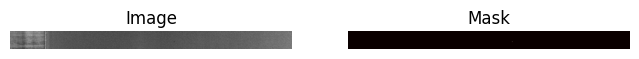

Image: 0101_022_03.png, Mask: 0101_022_03_mask.png
Mask array (unique values): [  0  10  20  30  52  73  95 106 117 128 140 163 175 198 210 211 213 214
 215 216 217 218 219 220 221 223 224 225 226 227 228 230 232 234 235 236
 237 238 239 240 241 243 244 245 246 247 248 249 250 251 252]
Nonzero pixel count (mask > 0): 278
Nonzero pixel count (mask > 127): 260
This mask contains defect pixels (mask > 127).
Nonzero pixel indices (mask > 127): [[   4 1295]
 [   4 1296]
 [   5 1293]
 [   5 1294]
 [   5 1295]
 [   5 1296]
 [   5 1297]
 [   6 1293]
 [   6 1294]
 [   6 1295]
 [   6 1296]
 [   6 1297]
 [   6 1298]
 [   7 1292]
 [   7 1293]
 [   7 1294]
 [   7 1295]
 [   7 1296]
 [   7 1297]
 [   7 1298]
 [   7 1299]
 [   8 1292]
 [   8 1293]
 [   8 1294]
 [   8 1295]
 [   8 1296]
 [   8 1297]
 [   8 1298]
 [   8 1299]
 [   8 1300]
 [   9 1292]
 [   9 1293]
 [   9 1294]
 [   9 1295]
 [   9 1296]
 [   9 1297]
 [   9 1298]
 [   9 1299]
 [   9 1300]
 [   9 1301]
 [  10 1292]
 [  10 1293]
 [  10 129

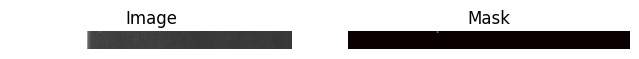

Image: 0054_019_03.png, Mask: 0054_019_03_mask.png
Mask array (unique values): [  0   8  52 159 184 185 186 187 199 204 206 208 210 211 212 213 214 215
 216 217 222 232 233 237 238 240 241 246 247 248]
Nonzero pixel count (mask > 0): 40
Nonzero pixel count (mask > 127): 38
This mask contains defect pixels (mask > 127).
Nonzero pixel indices (mask > 127): [[ 179 1341]
 [ 179 1342]
 [ 179 1343]
 [ 179 1344]
 [ 180 1341]
 [ 180 1342]
 [ 180 1343]
 [ 180 1344]
 [ 181 1341]
 [ 181 1342]
 [ 181 1343]
 [ 181 1344]
 [ 182 1341]
 [ 182 1342]
 [ 182 1343]
 [ 182 1344]
 [ 182 1345]
 [ 182 1346]
 [ 182 1347]
 [ 182 1348]
 [ 182 1349]
 [ 183 1341]
 [ 183 1342]
 [ 183 1343]
 [ 183 1344]
 [ 183 1345]
 [ 183 1346]
 [ 183 1347]
 [ 183 1348]
 [ 183 1349]
 [ 184 1342]
 [ 184 1343]
 [ 184 1344]
 [ 184 1345]
 [ 184 1346]
 [ 184 1347]
 [ 184 1348]
 [ 184 1349]]


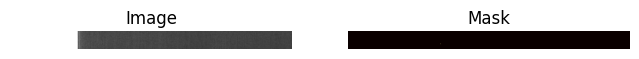

Image: 0066_023_01.png, Mask: 0066_023_01_mask.png
Mask array (unique values): [  0   8  17  26  35  44  53  62  71  81  90 100 110 120 130 140 150 161
 171 181 182 183 184 185 186 187 188 189 190 193 194 195 196 197 198 199
 200 201 202 203 204 205 206 207 208 209 210 211 212 213 214 215 216 217
 218 219 220 221 222 223 224 225 226 227 228 229 230 231 232 233 234 235
 236 237 239 240 241 242 243 245 246 247 248 249]
Nonzero pixel count (mask > 0): 583
Nonzero pixel count (mask > 127): 469
This mask contains defect pixels (mask > 127).
Nonzero pixel indices (mask > 127): [[   1 2239]
 [   1 2240]
 [   2 2239]
 [   2 2240]
 [   3 2239]
 [   3 2240]
 [   4 2239]
 [   4 2240]
 [   5 2240]
 [   5 2241]
 [   6 2240]
 [   6 2241]
 [   6 2242]
 [   7 2240]
 [   7 2241]
 [   7 2242]
 [   8 2241]
 [   8 2242]
 [   9 2242]
 [   9 2243]
 [  10 2242]
 [  10 2243]
 [  11 2242]
 [  11 2243]
 [  12 2244]
 [  13 2244]
 [  14 2244]
 [  14 2245]
 [  15 2244]
 [  15 2245]
 [  16 2244]
 [  16 2245]
 [  16

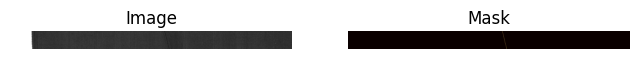

In [407]:
import random

def visualize_random_samples(image_paths, mask_paths, num_samples=5):
    print("Checking mask-image matching and visualizing samples...")
    indices = random.sample(range(len(image_paths)), min(num_samples, len(image_paths)))
    for idx in indices:
        img = cv2.imread(image_paths[idx], cv2.IMREAD_GRAYSCALE)
        mask = cv2.imread(mask_paths[idx], cv2.IMREAD_GRAYSCALE)
        if img is None or mask is None:
            print(f"Could not read: {image_paths[idx]} or {mask_paths[idx]}")
            continue
        print(f"Image: {os.path.basename(image_paths[idx])}, Mask: {os.path.basename(mask_paths[idx])}")
        print("Mask array (unique values):", np.unique(mask))
        print("Nonzero pixel count (mask > 0):", np.count_nonzero(mask))
        binary_mask = (mask > 127).astype(np.uint8)
        print("Nonzero pixel count (mask > 127):", np.count_nonzero(binary_mask))
        if np.count_nonzero(binary_mask) == 0:
            print("WARNING: This mask is all zeros (background only).")
        else:
            print("This mask contains defect pixels (mask > 127).")
        # Optionally, print nonzero indices if you want to debug further
        # print("Nonzero pixel indices (if any):", np.argwhere(mask > 127))
        print("Nonzero pixel indices (mask > 127):", np.argwhere(binary_mask))
        plt.figure(figsize=(8,3))
        plt.subplot(1,2,1)
        plt.imshow(img, cmap='gray')
        plt.title('Image')
        plt.axis('off')
        plt.subplot(1,2,2)
        plt.imshow(mask, cmap='hot')
        plt.title('Mask')
        plt.axis('off')
        plt.show()

# Example usage for validation set:
visualize_random_samples(val_images, val_masks, num_samples=5)

In [408]:
def check_patch_distribution(dataset_obj):
    defect_count = sum(dataset_obj.labels)
    total = len(dataset_obj.labels)
    print(f"Total patches: {total}")
    print(f"Defect patches: {defect_count} ({100*defect_count/total:.1f}%)")
    print(f"Non-defect patches: {total-defect_count} ({100*(total-defect_count)/total:.1f}%)")

print("Validation patch distribution:")
check_patch_distribution(val_dataset_obj)
print("Training patch distribution:")
check_patch_distribution(train_dataset_obj)

Validation patch distribution:
Total patches: 232
Defect patches: 85 (36.6%)
Non-defect patches: 147 (63.4%)
Training patch distribution:
Total patches: 960
Defect patches: 348 (36.2%)
Non-defect patches: 612 (63.8%)


Visualizing defect patches from validation set...
Patch index: 107, Defect pixels: 0


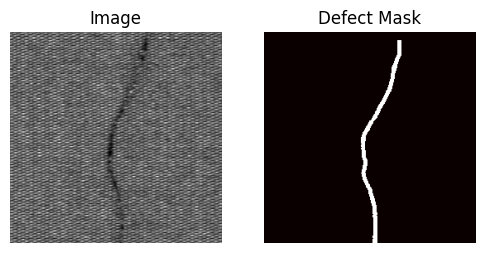

Patch index: 39, Defect pixels: 0


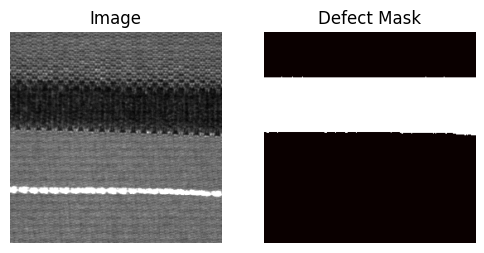

Patch index: 63, Defect pixels: 0


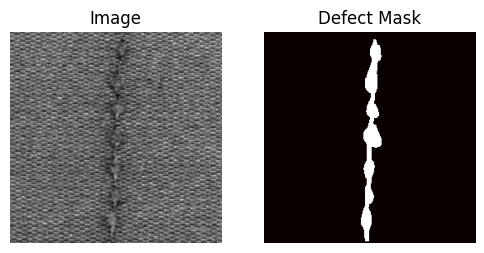

In [409]:
def visualize_defect_patches(dataset_obj, num_samples=5):
    print("Visualizing defect patches from validation set...")
    defect_indices = [i for i, label in enumerate(dataset_obj.labels) if label == 1]
    if not defect_indices:
        print("No defect patches found in validation set!")
        return
    indices = random.sample(defect_indices, min(num_samples, len(defect_indices)))
    for idx in indices:
        img, mask = dataset_obj.get_item(idx)
        binary_mask = (mask[:,:,0] > 127).astype(np.uint8)
        defect_pixels = np.count_nonzero(binary_mask)
        print(f"Patch index: {idx}, Defect pixels: {defect_pixels}")
        plt.figure(figsize=(6,3))
        plt.subplot(1,2,1)
        plt.imshow(img[:,:,0], cmap='gray')
        plt.title('Image')
        plt.axis('off')
        plt.subplot(1,2,2)
        plt.imshow(mask[:,:,0], cmap='hot')
        plt.title('Defect Mask')
        plt.axis('off')
        plt.show()

visualize_defect_patches(val_dataset_obj, num_samples=3)

Showing largest defect patches (by defect area):


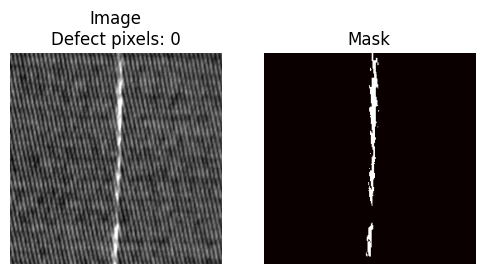

Patch index: 0, Defect pixels: 0


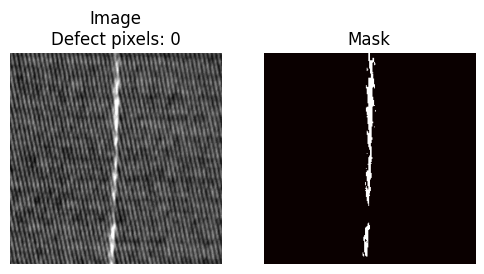

Patch index: 1, Defect pixels: 0


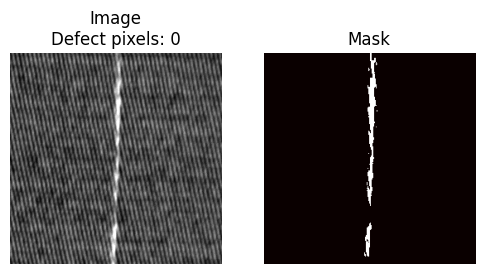

Patch index: 2, Defect pixels: 0


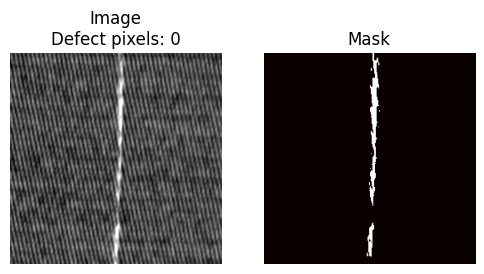

Patch index: 3, Defect pixels: 0


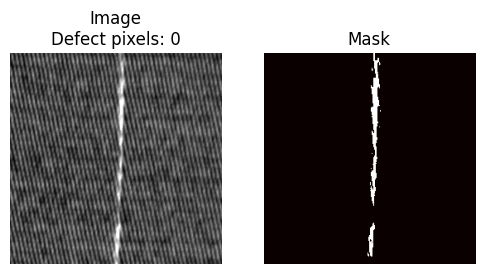

Patch index: 4, Defect pixels: 0
Showing smallest defect patches (by defect area):


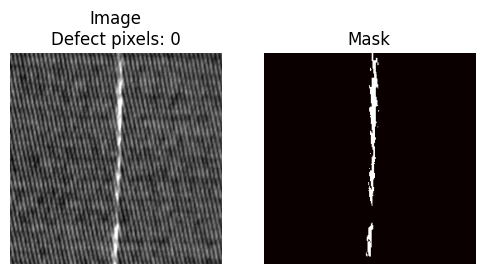

Patch index: 0, Defect pixels: 0


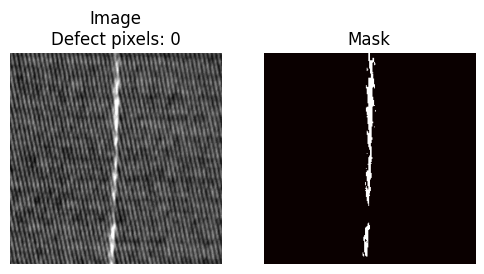

Patch index: 1, Defect pixels: 0


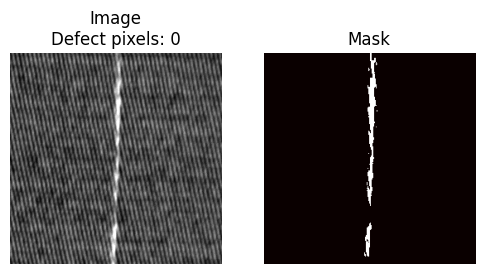

Patch index: 2, Defect pixels: 0


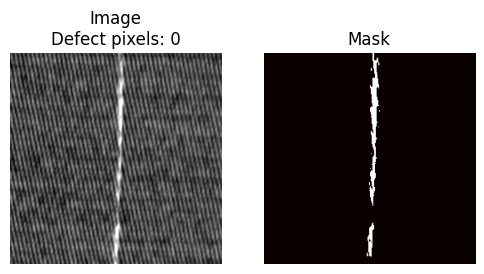

Patch index: 3, Defect pixels: 0


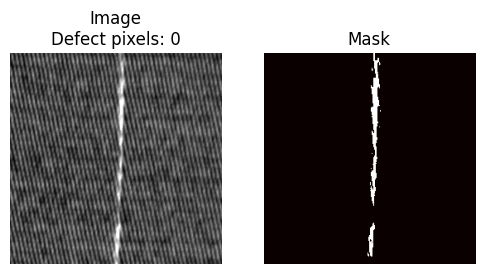

Patch index: 4, Defect pixels: 0


In [410]:
import matplotlib.pyplot as plt
import numpy as np

def visualize_defect_patches_by_size(dataset_obj, num_samples=5, largest=True):
    """
    Visualize defect patches with the largest or smallest defect area.
    Set largest=True to see the largest, False for the smallest.
    """
    # Collect all defect patch indices and their defect pixel counts
    defect_info = []
    for idx, label in enumerate(dataset_obj.labels):
        if label == 1:
            _, mask = dataset_obj.get_item(idx)
            binary_mask = (mask[:,:,0] > 127).astype(np.uint8)
            defect_pixels = np.count_nonzero(binary_mask)
            defect_info.append((idx, defect_pixels))
    if not defect_info:
        print("No defect patches found in this dataset!")
        return
    # Sort by defect pixel count
    defect_info.sort(key=lambda x: x[1], reverse=largest)
    print(f"Showing {'largest' if largest else 'smallest'} defect patches (by defect area):")
    for i in range(min(num_samples, len(defect_info))):
        idx, defect_pixels = defect_info[i]
        img, mask = dataset_obj.get_item(idx)
        plt.figure(figsize=(6,3))
        plt.subplot(1,2,1)
        plt.imshow(img[:,:,0], cmap='gray')
        plt.title(f'Image\nDefect pixels: {defect_pixels}')
        plt.axis('off')
        plt.subplot(1,2,2)
        plt.imshow(mask[:,:,0], cmap='hot')
        plt.title('Mask')
        plt.axis('off')
        plt.show()
        print(f"Patch index: {idx}, Defect pixels: {defect_pixels}")

# Example usage for validation set:
visualize_defect_patches_by_size(val_dataset_obj, num_samples=5, largest=True)   # Largest defects
visualize_defect_patches_by_size(val_dataset_obj, num_samples=5, largest=False)  # Smallest defects

In [411]:
defect_indices = [i for i, label in enumerate(val_dataset_obj.labels) if label == 1]
print("Number of unique defect patches in validation set:", len(defect_indices))
print("Patch indices:", defect_indices)

Number of unique defect patches in validation set: 85
Patch indices: [0, 1, 2, 3, 4, 5, 6, 7, 12, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 56, 57, 58, 59, 60, 61, 62, 63, 72, 73, 74, 75, 76, 77, 78, 79, 84, 88, 89, 90, 91, 92, 93, 94, 95, 104, 105, 106, 107, 108, 109, 110, 111, 119, 120, 121, 122, 123, 124, 125, 126, 127, 134, 144, 145, 146, 147, 148, 149, 150, 151, 156]


In [412]:
train_basenames = set([os.path.basename(p) for p in train_images])
val_basenames = set([os.path.basename(p) for p in val_images])
intersection = train_basenames.intersection(val_basenames)
if intersection:
    print("WARNING: The following images are present in both train and validation sets (possible data leakage):")
    print(list(intersection))
else:
    print("No data leakage detected: train and validation sets are disjoint by image filename.")

No data leakage detected: train and validation sets are disjoint by image filename.


In [413]:
# Custom metrics for Keras
def dice_coef(y_true, y_pred, smooth=1e-6):
    y_true_f = tf.reshape(y_true, [-1])
    y_pred_f = tf.reshape(y_pred, [-1])
    intersection = tf.reduce_sum(y_true_f * y_pred_f)
    return (2. * intersection + smooth) / (tf.reduce_sum(y_true_f) + tf.reduce_sum(y_pred_f) + smooth)

def iou_coef(y_true, y_pred, smooth=1e-6):
    y_true_f = tf.reshape(y_true, [-1])
    y_pred_f = tf.reshape(y_pred, [-1])
    intersection = tf.reduce_sum(y_true_f * y_pred_f)
    union = tf.reduce_sum(y_true_f) + tf.reduce_sum(y_pred_f) - intersection
    return (intersection + smooth) / (union + smooth)

def recall_m(y_true, y_pred):
    y_true_f = tf.reshape(y_true, [-1])
    y_pred_f = tf.reshape(y_pred, [-1])
    true_positives = tf.reduce_sum(y_true_f * y_pred_f)
    possible_positives = tf.reduce_sum(y_true_f)
    return true_positives / (possible_positives + 1e-6)

def precision_m(y_true, y_pred):
    y_true_f = tf.reshape(y_true, [-1])
    y_pred_f = tf.reshape(y_pred, [-1])
    true_positives = tf.reduce_sum(y_true_f * y_pred_f)
    predicted_positives = tf.reduce_sum(y_pred_f)
    return true_positives / (predicted_positives + 1e-6)

def f1_m(y_true, y_pred):
    precision = precision_m(y_true, y_pred)
    recall = recall_m(y_true, y_pred)
    return 2*((precision*recall)/(precision+recall+1e-6))

In [414]:
# Example: Training and comparing Attention U-Net and HRNet

# Build datasets
# (Assume train_dataset and val_dataset are already created as in your pipeline)

# Build models
attention_unet_model = build_attention_unet(input_shape=(Config.PATCH_SIZE, Config.PATCH_SIZE, 1), filters_base=32)
hrnet_model = build_hrnet(input_shape=(Config.PATCH_SIZE, Config.PATCH_SIZE, 1), base_filters=32)

# Compile models
for model in [attention_unet_model, hrnet_model]:
    model.compile(
        optimizer=tf.keras.optimizers.AdamW(
            learning_rate=Config.LEARNING_RATE,
            weight_decay=1e-4
        ),
        loss=combined_loss,
        metrics=[
            'accuracy',
            dice_coef,
            iou_coef,
            recall_m,
            precision_m,
            f1_m
        ]
    )


# Train Attention U-Net
print("\nTraining Attention U-Net model...")
history_attention_unet = attention_unet_model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=Config.EPOCHS,
    callbacks=callbacks_list,
    verbose=1
)

# Train HRNet
print("\nTraining HRNet model...")
history_hrnet = hrnet_model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=Config.EPOCHS,
    callbacks=callbacks_list,
    verbose=1
)

# Plot training histories
print("\nPlotting Attention U-Net training history...")
plot_training_history(history_attention_unet)
print("\nPlotting HRNet training history...")
plot_training_history(history_hrnet)

# Evaluate and compare
print("\nEvaluating Attention U-Net model...")
best_thresh_unet, best_metrics_unet = multi_threshold_evaluation(attention_unet_model, val_dataset)
print("\nEvaluating HRNet model...")
best_thresh_hrnet, best_metrics_hrnet = multi_threshold_evaluation(hrnet_model, val_dataset)

print("\nAttention U-Net Best Metrics:", best_metrics_unet)
print("HRNet Best Metrics:", best_metrics_hrnet)


Training Attention U-Net model...
Epoch 1/200


KeyboardInterrupt: 